# 1. Вывод формул для градиентов
Сначала рассмотрим случай одного примера. Обозначим нейросеть следующим образом:
* Вход: $x \in \mathbb{R}^{w h}$. Одноканальное изображение размером $w \times h$
* Аффинное преобразование первого (скрытого) слоя: $z^{(1)} = W^{(1)}x+b^{(1)}$. $z^{(1)} \in \mathbb{R}^{s}$
* Активация первого (скрытого) слоя: $a^{(1)} = \mathrm{ReLU}(z^{(1)})$. $a^{(1)} \in \mathbb{R}^{s}$
* Аффинное преобразование второго (выходного) слоя: $z^{(2)} =  W^{(2)}a^{(1)}+b^{(2)}$. $z^{(2)} \in \mathbb{R}^{k}$
* Выход, активация второго (выходного) слоя: $a^{(2)} = \mathrm{softmax}(z^{(2)})$. $a^{(2)} \in \mathbb{R}^{k}$

Пусть ожидаемый выход в терминах one-hot-encoding есть $y \in \{0,1\}^k$, где $k$ количество классов. Для изображения класса $i$ имеем 
$y = e_i$, где $e_i$ --- $i$-й базисный вектор.
В качестве лосс-функции используем кросс-энтропию
$$
    L(a^{(2)}) = - \sum_{j = 1}^k y_j \log{a^{(2)}_j} = - y^T\log{a^{(2)}} .
$$

Нам необходимо последовательно посчитать величины $\frac{\partial L}{\partial W^{(1)}}, \frac{\partial L}{\partial b^{(1)}}, \frac{\partial L}{\partial W^{(2)}}, \frac{\partial L}{\partial b^{(2)}}$.

Посчитаем необходимые градиенты и якобианы. Для начала градиент лосса
$$\frac{\partial L}{\partial a_i^{(2)}} = - \frac{y_i}{a_i^{(2)}}, i = 1, \ldots, k.$$
Затем якобиан softmax-а
$$\frac{\partial  a_i^{(2)}}{\partial z_j^{(2)}} = \frac{\partial }{\partial z_j^{(2)}} \Bigl( \frac{e^{z_i^{(2)}}}{\sum_{l = 1}^{k}e^{z_l^{(2)}}}\Bigr) = \frac{\Bigl(\sum_{l = 1}^{k}e^{z_l^{(2)}}\Bigr)\frac{\partial }{\partial z_j^{(2)}}(e^{z_i^{(2)}}) -e^{z_i^{(2)}} \frac{\partial }{\partial z_j^{(2)}}\Bigl(\sum_{l = 1}^{k}e^{z_l^{(2)}}\Bigr)}{\Bigl(\sum_{l = 1}^{k}e^{z_l^{(2)}}\Bigr)^2} = \frac{\Bigl(\sum_{l = 1}^{k}e^{z_l^{(2)}}\Bigr)e^{z_i^{(2)}} \delta_{i,j} -e^{z_i^{(2)}} e^{z_j^{(2)}}}{\Bigl(\sum_{l = 1}^{k}e^{z_l^{(2)}}\Bigr)^2} = a_i^{(2)} (\delta_{i,j} - a_j^{(2)}),$$
где $\delta_{i,j} = \begin{cases} 1, i=j\\ 0, i\not=j\end{cases}$ --- дельта Кронекера. Теперь запишем
$$\frac{\partial L}{\partial z_j^{(2)}} = \sum_{i = 1}^k \frac{\partial L}{\partial a_i^{(2)}}\frac{\partial  a_i^{(2)}}{\partial z_j^{(2)}} = \sum_{i = 1}^k - \frac{y_i}{a_i^{(2)}} a_i^{(2)} (\delta_{i,j} - a_j^{(2)}) = -y_j + a_j^{(2)} \underbrace{\sum_{i = 1}^k y_i}_{=1} = a_j^{(2)} -  y_j,$$
откуда
$$\frac{\partial L}{\partial z^{(2)}} =a^{(2)} -  y = g^{(2)}.$$
Теперь мы будем считать 
$ g^{(1)} = \frac{\partial L}{\partial z^{(1)}}$. Чтобы это сделать, сначала получим
$$
    \frac{\partial L}{\partial a_j^{(1)}} = \sum_{i=1}^k \frac{\partial L}{\partial z_i^{(2)}} \frac{\partial z_i^{(2)}}{\partial a_j^{(1)}} = \sum_{i=1}^k g_i^{(2)} W_{i,j}^{(2)} = W_j^{(2)T} g^{(2)},
$$
откуда 
$$
    \frac{\partial L}{\partial a^{(1)}} = W^{(2)T} g^{(2)}.
$$
Теперь заметим, что $a_i^{(1)} = \mathrm{ReLU}(z_i^{(1)}) = \max{(0,z_i^{(1)})}$, производная
$$
    \mathrm{ReLU}'(z) = \begin{cases} 1, z >0 \\ 0, z \leq 0\end{cases}.
$$
Отсюда
$$ 
    \frac{\partial L}{\partial z_l^{(1)}} = \frac{\partial L}{\partial a_l^{(1)}} \mathrm{ReLU}'(z_l^{(1)})
$$ и
$$
    g^{(1)} = \frac{\partial L}{\partial z^{(1)}} = (W^{(2)T} g^{(2)}) \odot \mathrm{ReLU}'(z^{(1)}) = (W^{(2)T} g^{(2)}) \odot 1[z^{(1)} > 0],
$$
где $\odot$ означает поэлементное умножение. Далее переходим к подсчёту искомых градиентов:
$$
    z_i^{(2)} = \sum_{j = 1}^s W_{i,j}^{(2)}a_j^{(1)}+b_i^{(2)},
$$
$$
    \frac{\partial z_i^{(2)}}{\partial W_{i,j}^{(2)}} = a_j^{(1)},
$$
$$
    \frac{\partial L}{\partial W_{i,j}^{(2)}} = g^{(2)}_i  a_j^{(1)},
$$
$$
     \frac{\partial L}{\partial W^{(2)}} = g^{(2)} a^{(1)T}.
$$
Аналогично
$$
    \frac{\partial L}{\partial b^{(2)}} = g^{(2)}.
$$
Таким же образом получаем 
$$
    \frac{\partial L}{\partial W^{(1)}} = g^{(1)} x^{T}
$$ и
$$
    \frac{\partial L}{\partial b^{(1)}} = g^{(1)}.
$$
Когда у нас не один пример, а пачка из $N$ примеров, батч, мы меняем лосс на среднюю кросс-энтропию по пачке. Обозначим большими буквами те же величины, собранные в матрицы по столбцам-примерам. Тогда 
$$
    L = - \frac{1}{N} \sum_{n=1}^N y_n^T\log{a_n^{(2)}} = - \frac{1}{N} \sum_{n=1}^N \sum_{j=1}^k Y_{j,n}\log{A_{j,n}^{(2)}}
$$
и константу мы можем внести лишь в
$$
    G^{(2)} = \frac{1}{N} (A^{(2)} -  Y),
$$
поскольку $G^{(1)}$ и частные производные по весам и сдвигам зависят от этой величины линейно. Тогда имеем
$$
    G^{(1)} = \bigl(W^{(2)\top} G^{(2)}\bigr) \odot \mathbf{1}[Z^{(1)} > 0],,
$$
$$
    \frac{\partial L}{\partial W^{(2)}} = G^{(2)} A^{(1)T},
$$
$$
    \frac{\partial L}{\partial b^{(2)}} = G^{(2)} 1_N,
$$
где $1_N$ --- вектор-столбец из $N$ единиц. Далее
$$
    \frac{\partial L}{\partial W^{(1)}} = G^{(1)} X^{T},
$$
$$
    \frac{\partial L}{\partial b^{(1)}} = G^{(1)} 1_N.
$$

Пусть скорость обучения есть $\eta$, тогда шаг градиентного спуска в простейшей форме имеет вид
$$
    \begin{cases} 
        W^{(1)}_{\mathrm{new}} = W^{(1)}_{\mathrm{old}} - \eta \frac{\partial L}{\partial W^{(1)}};\\
        b^{(1)}_{\mathrm{new}} = b^{(1)}_{\mathrm{old}} - \eta \frac{\partial L}{\partial b^{(1)}};\\
        W^{(2)}_{\mathrm{new}} = W^{(2)}_{\mathrm{old}} - \eta \frac{\partial L}{\partial W^{(2)}};\\
        b^{(2)}_{\mathrm{new}} = b^{(2)}_{\mathrm{old}} - \eta \frac{\partial L}{\partial b^{(2)}}.\\
    \end{cases}
$$

# 2. Загружаем датасет

**Загружаем данные**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="auto")

X_raw = mnist.data
y_raw = mnist.target

In [2]:
print(type(mnist))
print("X_raw:", X_raw.shape, X_raw.dtype)
print("y_raw:", y_raw.shape, y_raw.dtype)
print("Первые 10 меток:", y_raw[:10])
print("Диапазон пикселей:", X_raw.min(), X_raw.max())

<class 'sklearn.utils._bunch.Bunch'>
X_raw: (70000, 784) int64
y_raw: (70000,) object
Первые 10 меток: ['5' '0' '4' '1' '9' '2' '1' '3' '1' '4']
Диапазон пикселей: 0 255


**Предобрабатываем**

1. Пикселям делаем тип float32 и диапазон $[0,1]$. Меткам сопоставляем целые числа от $0$ до $9$.

In [3]:
X = X_raw.astype(np.float32) / 255.0
y = y_raw.astype(np.int64)

print("X:", X.shape, X.dtype, X.min(), X.max())
print("y:", y.shape, y.dtype, y[:10])
print("Уникальные метки:", np.unique(y))

X: (70000, 784) float32 0.0 1.0
y: (70000,) int64 [5 0 4 1 9 2 1 3 1 4]
Уникальные метки: [0 1 2 3 4 5 6 7 8 9]


2. One-hot-encoding. Каждой метке сопоставляем бинарный вектор длины $10$ с единицей в нужной числовой позиции. Например, $0$ соответствует $[1,0,0,0,0,0,0,0,0,0]$. Это понадобится, чтобы в векторном виде кросс-энтропию считать.

In [4]:
def one_hot(y, k=10):
    Y = np.zeros((y.shape[0], k), dtype=np.float32)
    Y[np.arange(y.shape[0]), y] = 1.0
    return Y

In [5]:
Y = one_hot(y)

print("Y:", Y.shape, Y.dtype)
print("y[0] =", y[0], " -> ", Y[0])
print("y[1] =", y[1], " -> ", Y[1])
print("Сумма по строке (должна быть 1):", Y[0].sum())

Y: (70000, 10) float32
y[0] = 5  ->  [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
y[1] = 0  ->  [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Сумма по строке (должна быть 1): 1.0


3. Разделение на тестовую и тренировочную выборки. Транспонирование нужно для соответствия выкладкам для градиентов, которые проведены для векторов-столбцов.

In [6]:
n_train = 60_000

X_train, X_test = X[:n_train].T, X[n_train:].T
y_train, y_test = y[:n_train], y[n_train:]
Y_train, Y_test = Y[:n_train].T, Y[n_train:].T

print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)
print("Y_train:", Y_train.shape, "Y_test:", Y_test.shape)
print("Train counts:", np.bincount(y_train))
print("Test  counts:", np.bincount(y_test))

X_train: (784, 60000) X_test: (784, 10000)
y_train: (60000,) y_test: (10000,)
Y_train: (10, 60000) Y_test: (10, 10000)
Train counts: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
Test  counts: [ 980 1135 1032 1010  982  892  958 1028  974 1009]


**Смотрим, что сейчас есть**

In [7]:
print("Примеров в train:", X_train.shape[1])
print("Примеров в test: ", X_test.shape[1])
print("X_train:", X_train.shape, "  X_test:", X_test.shape)
print("Одно изображение flatten:", X_train[:, 0].shape, "  как картинка:", (28, 28))
print("y_train:", y_train.shape, y_train.dtype, "  одна метка:", int(y_train[0]))
print("y_test:", y_test.shape)
print("Y_train (one-hot):", Y_train.shape, "  пример:", Y_train[:, 0])
print("Y_test  (one-hot):", Y_test.shape)

Примеров в train: 60000
Примеров в test:  10000
X_train: (784, 60000)   X_test: (784, 10000)
Одно изображение flatten: (784,)   как картинка: (28, 28)
y_train: (60000,) int64   одна метка: 5
y_test: (10000,)
Y_train (one-hot): (10, 60000)   пример: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
Y_test  (one-hot): (10, 10000)


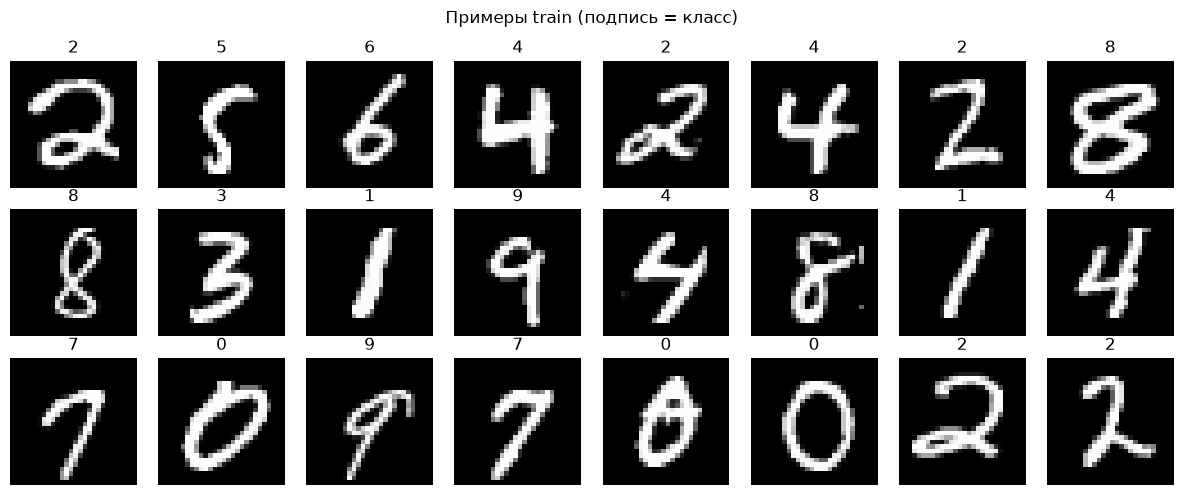

In [8]:
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
rng = np.random.default_rng(0)
idx = rng.choice(X_train.shape[1], size=axes.size, replace=False)

for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_train[:,i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(str(int(y_train[i])))
    ax.axis("off")

fig.suptitle("Примеры train (подпись = класс)")
plt.tight_layout()

# 3. Инициализация весов

Мы применяем метод инициализации весов через нормальное распределение с нулевым средним и дисперсией порядка $\frac{2}{\text{размер вх. слоя}}$ (He). Это нужно, потому что активация $\mathrm{ReLU}$ обнуляет примерно половину нейронов и чтобы второй момент после активации совпал со вторым моментом до активации нам нужно его масштабировать.  Так скрытый слой не схлопывает сигнал в ноль и не раздувает его.

In [9]:
s = 300 # Размер скрытого слоя
n_in = 28 * 28 # Входов
n_out = 10 # Выходов

rng = np.random.default_rng(42)

W1 = rng.normal(0.0, np.sqrt(2.0 / n_in), size=(s, n_in)).astype(np.float32)
b1 = np.zeros((s, 1), dtype=np.float32)

W2 = rng.normal(0.0, np.sqrt(2.0 / s),    size=(n_out, s)).astype(np.float32)
b2 = np.zeros((n_out, 1), dtype=np.float32)

print("s =", s)
print("W1", W1.shape, ", ожидали", (s, n_in),
      "; std", float(W1.std()), ", ожидали", float(np.sqrt(2 / n_in)))
print("b1", b1.shape, ", ожидали", (s, 1))
print("W2", W2.shape, ", ожидали", (n_out, s),
      "; std", float(W2.std()), ", ожидали", float(np.sqrt(2 / s)))
print("b2", b2.shape, ", ожидали", (n_out, 1))

s = 300
W1 (300, 784) , ожидали (300, 784) ; std 0.05058949813246727 , ожидали 0.050507627227610534
b1 (300, 1) , ожидали (300, 1)
W2 (10, 300) , ожидали (10, 300) ; std 0.0799894779920578 , ожидали 0.08164965809277261
b2 (10, 1) , ожидали (10, 1)


# 4. Forward

In [10]:
# Основные функции
def relu(Z):
    return np.maximum(Z, 0.0) # Поэлементный максимум

# Для softmax используем численный трюк: если домножить и числитель и знаменатель дроби на одно и то же число, то значение дроби не поменяется, 
# поэтому можно сдвинуть значения на константу, чтобы экспоненты НЕ взрывались
def softmax(Z):
    Zs = Z - Z.max(axis=0, keepdims=True) # Вычитаем max по классам в каждом примере
    E = np.exp(Zs)
    return E / E.sum(axis=0, keepdims=True)

def forward(X, W1, b1, W2, b2):
    Z1 = W1 @ X + b1# (s, N)
    A1 = relu(Z1) # (s, N)
    Z2 = W2 @ A1 + b2 # (k, N)
    A2 = softmax(Z2) # (k, N)
    cache = (X, Z1, A1, Z2, A2)
    return A2, cache

Проверим, как они работают на батче 

In [11]:
N_check = 8
X_b = X_train[:, :N_check] # (784, 8)

A2, cache = forward(X_b, W1, b1, W2, b2)
X_c, Z1, A1, Z2, A2_c = cache

print("X ", X_b.shape, "ждали", (n_in, N_check))
print("Z1", Z1.shape,  "ждали", (s, N_check))
print("A1", A1.shape,  "ждали", (s, N_check), "min", float(A1.min()))  # >= 0
print("Z2", Z2.shape,  "ждали", (n_out, N_check))
print("A2", A2.shape,  "ждали", (n_out, N_check))
print("Сумма по классам (должны быть ~1):", A2.sum(axis=0))
print(" Прогноз классов:", A2.argmax(axis=0), "истинные:", y_train[:N_check])

X  (784, 8) ждали (784, 8)
Z1 (300, 8) ждали (300, 8)
A1 (300, 8) ждали (300, 8) min 0.0
Z2 (10, 8) ждали (10, 8)
A2 (10, 8) ждали (10, 8)
Сумма по классам (должны быть ~1): [0.99999994 0.9999999  1.         1.         1.         0.9999999
 0.99999994 1.        ]
 Прогноз классов: [7 3 4 5 7 2 7 3] истинные: [5 0 4 1 9 2 1 3]


# 5. Backward

Мы используем то, что вывели в теории, но поделим лосс на размер батча, чтобы было усреднение по батчу. Для этого достаточно поделить выражение с $g_2$ на $N$ и градиенты сами подтянутся.

In [12]:
N = 32 # Размер батча

def cross_entropy(A2, Y, eps=1e-12):
    # средняя CE по столбцам; Y — one-hot (k, N)
    return float(-np.sum(Y * np.log(A2 + eps)) / N) # Для численной устойчивости добавляем регуляризацию

In [13]:
def backward(Y, cache, W2):
    X, Z1, A1, Z2, A2 = cache

    G2 = (A2 - Y) / N # Для усреднения по батчу
    dW2 = G2 @ A1.T
    db2 = G2.sum(axis=1, keepdims=True) # Сумма по батчу

    G1 = (W2.T @ G2) * (Z1 > 0)
    dW1 = G1 @ X.T
    db1 = G1.sum(axis=1, keepdims=True) # Сумма по батчу

    return dW1, db1, dW2, db2

Проверяем правильность.

In [14]:
X_b = X_train[:, :N]
Y_b = Y_train[:, :N]

A2, cache = forward(X_b, W1, b1, W2, b2)
dW1, db1, dW2, db2 = backward(Y_b, cache, W2)

print("loss", cross_entropy(A2, Y_b))
print("dW1", dW1.shape, "ждали", W1.shape)
print("db1", db1.shape, "ждали", b1.shape)
print("dW2", dW2.shape, "ждали", W2.shape)
print("db2", db2.shape, "ждали", b2.shape)

loss 2.2522261142730713
dW1 (300, 784) ждали (300, 784)
db1 (300, 1) ждали (300, 1)
dW2 (10, 300) ждали (10, 300)
db2 (10, 1) ждали (10, 1)


# 6. Цикл обучения

In [15]:
n_epochs = 20
lr = 0.1
rng = np.random.default_rng(0)
n_train = X_train.shape[1]
assert n_train % N == 0

In [16]:
# Точность классификации
def accuracy(A2, y):
    return float(np.mean(A2.argmax(axis=0) == y))

# Ошибка классицикации
def class_error(A2, y):
    return float(np.mean(A2.argmax(axis=0) != y))

Начинаем цикл обучения по батчу, сохраняя результаты

In [17]:
hist_epoch = []
hist_loss = []
hist_train_err = []
hist_time = []

In [18]:
import time

n_batches = n_train // N

for epoch in range(n_epochs):
    t0 = time.perf_counter()

    perm = rng.permutation(n_train)
    X_shuf = X_train[:, perm]
    Y_shuf = Y_train[:, perm]

    epoch_loss = 0.0
    for t in range(n_batches):
        sl = slice(t * N, (t + 1) * N)
        X_b = X_shuf[:, sl]
        Y_b = Y_shuf[:, sl]

        A2, cache = forward(X_b, W1, b1, W2, b2)
        epoch_loss += cross_entropy(A2, Y_b)

        dW1, db1, dW2, db2 = backward(Y_b, cache, W2)
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

    A2_tr, _ = forward(X_train, W1, b1, W2, b2)
    train_err = class_error(A2_tr, y_train)
    dt = time.perf_counter() - t0
    mean_loss = epoch_loss / n_batches

    hist_epoch.append(epoch + 1)
    hist_loss.append(mean_loss)
    hist_train_err.append(train_err)
    hist_time.append(dt)

    print(
        f"epoch {epoch+1:02d}  "
        f"train error {train_err:.4f} ({100*train_err:.2f}%)  "
        f"time {dt:.2f} s"
    )

hist_epoch = np.array(hist_epoch)
hist_loss = np.array(hist_loss)
hist_train_err = np.array(hist_train_err)
hist_time = np.array(hist_time)

A2_te, _ = forward(X_test, W1, b1, W2, b2)
test_err = class_error(A2_te, y_test)
print(f"test error {test_err:.4f} ({100*test_err:.2f}%)")

epoch 01  train error 0.0410 (4.10%)  time 3.02 s
epoch 02  train error 0.0302 (3.02%)  time 2.89 s
epoch 03  train error 0.0193 (1.93%)  time 2.98 s
epoch 04  train error 0.0148 (1.48%)  time 3.11 s
epoch 05  train error 0.0120 (1.20%)  time 3.04 s
epoch 06  train error 0.0105 (1.05%)  time 2.86 s
epoch 07  train error 0.0071 (0.71%)  time 2.99 s
epoch 08  train error 0.0053 (0.53%)  time 2.92 s
epoch 09  train error 0.0056 (0.56%)  time 2.93 s
epoch 10  train error 0.0045 (0.45%)  time 2.92 s
epoch 11  train error 0.0029 (0.29%)  time 2.95 s
epoch 12  train error 0.0017 (0.17%)  time 2.86 s
epoch 13  train error 0.0011 (0.11%)  time 2.84 s
epoch 14  train error 0.0011 (0.11%)  time 3.00 s
epoch 15  train error 0.0006 (0.06%)  time 2.96 s
epoch 16  train error 0.0006 (0.06%)  time 2.74 s
epoch 17  train error 0.0005 (0.05%)  time 2.97 s
epoch 18  train error 0.0004 (0.04%)  time 2.89 s
epoch 19  train error 0.0001 (0.01%)  time 2.92 s
epoch 20  train error 0.0001 (0.01%)  time 3.03 s


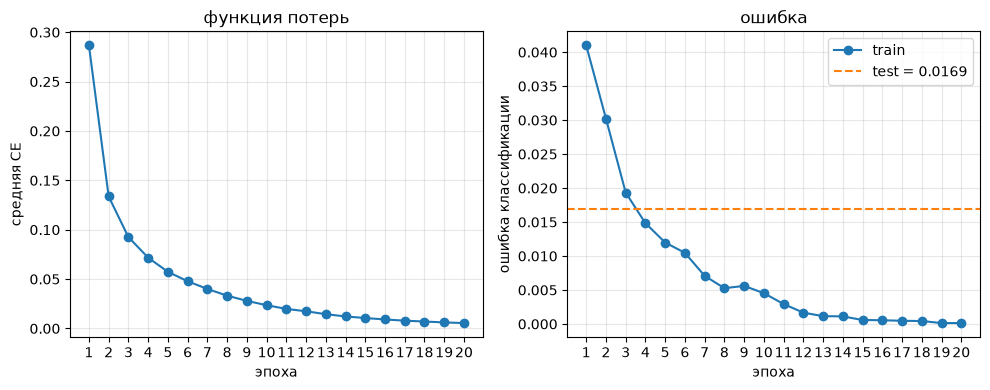

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(hist_epoch, hist_loss, marker="o")
ax[0].set_xlabel("эпоха")
ax[0].set_ylabel("средняя CE")
ax[0].set_title("функция потерь")
ax[0].grid(True, alpha=0.3)
ax[0].set_xticks(hist_epoch)

ax[1].plot(hist_epoch, hist_train_err, marker="o", label="train")
ax[1].axhline(test_err, color="C1", linestyle="--", label=f"test = {test_err:.4f}")
ax[1].set_xlabel("эпоха")
ax[1].set_ylabel("ошибка классификации")
ax[1].set_title("ошибка")
ax[1].legend()
ax[1].grid(True, alpha=0.3)
ax[1].set_xticks(hist_epoch)

fig.tight_layout()

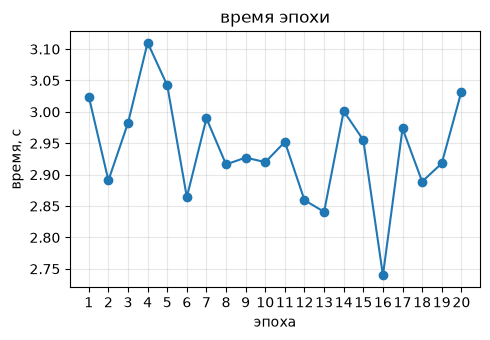

In [20]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(hist_epoch, hist_time, marker="o")
ax.set_xlabel("эпоха")
ax.set_ylabel("время, с")
ax.set_title("время эпохи")
ax.set_xticks(hist_epoch)
ax.grid(True, alpha=0.3)
fig.tight_layout()

In [21]:
test_acc = 1.0 - test_err
print(f"test accuracy {test_acc:.4f}  ({100 * test_acc:.2f}%)")
print(f"test error    {test_err:.4f}  ({100 * test_err:.2f}%)")

test accuracy 0.9831  (98.31%)
test error    0.0169  (1.69%)


**Достигнута точность $\sim 98\%$**